# Workshop 2 — from opening EDA to credible validation

**Group 03:** Javier Alcaíno, Lucas Riquelme and Renato Varela. **Version:** 21 October 2026.

This notebook continues the **reconstructed chess C1 baseline**, with the same
decision, observation unit, checkpoint and points KPI. The topic change from the
original school-audit project is documented rather than concealed. C1 is retained
alongside W2. No instructor feedback was available; all corrections below are
explicitly self-audits. This package is local at the team's request; no repository
upload, commit, tag or submission is claimed.

The outcome is an implemented data-validation and holdout strategy. **No predictive
model is trained and no performance score is fabricated.**

## 1. Continuity and measurement


| Step | Definition for this case |
|---|---|
| Decision | A proposed club training coordinator allocates opening-review sessions by speed, player level and color. No external stakeholder validation is claimed. |
| Success criteria | Provide traceable review priorities with adequate support. Actual learning gains or better future results would need intervention/follow-up data that are absent here. |
| Business question | How do opening-family exposure and observed points differ across rating bands, colors and blitz/rapid, and what can be predicted from a fixed opening checkpoint? |
| Business process | Choose a training focus, review representative games, run a session and monitor later performance. Only public games and outcomes are observed, not session attendance or effectiveness. |
| Entities, events and states | Players participate in standard rated games. At the position after Black's 10th move, a game has an observed opening prefix and later a win/draw/loss. |
| Data representation | One primary row is one unique game. A two-row color perspective table supports descriptive KPIs; it does not create independent games. The lookup joins observed board positions to an external opening taxonomy. |
| Measurement | Points per eligible player-game opportunity: (wins + 0.5 × draws) / eligible games in the same color × speed × rating band × opening-family cell. Also report exposure counts and shares. |

## Measurement contract and interpretation

The **primary KPI is observed points per game**, reported separately by focal color, speed,
rating band and opening family. A win contributes 1 point, a draw 0.5 and a loss 0.
The denominator includes all eligible completed games in that cell, including draws.
This is a descriptive score rate, **not** predictive accuracy, an estimated treatment effect,
or proof that studying an opening improves performance.

Opening family means the **last named reference position actually reached within the first
20 plies** (10 moves by each side). It is derived from the observed prefix, not copied from
the post-game Opening/ECO headers. The planned prediction occurs immediately after Black's
10th move, before a later resignation/action; games with a terminal board at that point or
without 20 observed plies are outside the checkpoint cohort. This creates survivor selection.

The rating bands are under 1200, 1200–1599, 1600–1999 and 2000+, using **Lichess Glicko-2
ratings**. Blitz and rapid ratings are not assumed interchangeable. These bands and the
50-game display threshold are transparent operational choices, not official ability labels
or guarantees of statistical precision. No club-specific numerical improvement target is invented.

Pooling both color perspectives would force the global mean to 50%: every game's two scores
sum to 1. We therefore never rank openings by a combined-color score.

### Feedback-to-action table

| Source | Issue in the C1 baseline | Correction / extension | Evidence below |
|---|---|---|---|
| Self-audit 1 | Unadjusted opening points were descriptive; within-band opponent imbalance remained a limitation. | Compare the same points KPI within a declared absolute rating gap ≤100 and show changed score estimates and exposure. Do not call the restriction causal adjustment. | Section 4, close-rating comparison table |
| Self-audit 2 | C1 proposed future prediction but had no implemented split or fitted preprocessing demonstration. | Export chronological train/validation/test datasets; fit scaler/encoder only on July and apply frozen rules to August/September. | Sections 5 and 7 |
| Self-audit 3 | C1 had a full-cohort EDA, so a later split cannot be advertised as perfectly untouched. | Freeze the feature contract and thresholds before W2; identify the existing exposure of the September outcomes and require genuinely new data for a confirmatory performance claim. | Sections 2, 6 and 7 |
| Self-audit 4 | Final opening tags were retained in source data for traceability and could be selected accidentally. | Explicit predictor allow-list, prefix-invariance check and measured tag disagreements; exclude all post-outcome columns. | Section 6 |
| Self-audit 5 | A 25% sample of observed windows could be mistaken for platform representativeness. | Compare KPI and segment share, then separate within-frame sampling from original frame selection and predictive splitting. | Section 5 |

These are not invented instructor quotations. Corrections revise the strength and
support of recommendations; the underlying observations and previous artifacts remain visible.

## 2. Predeclared analytical and validation contract


## Population, source coverage and extraction

**Intended population:** rated standard blitz and rapid games relevant to a club's training
planning across player levels. **Observed source:** three bounded UTC windows at the starts
of July, August and September 2026. **Analytical population:** unique, valid games in those
windows reaching a legal, nonterminal 20-ply checkpoint.

For each monthly official Lichess archive, the extraction reads exactly its first 16 MiB of
compressed bytes. It retains fully bounded PGN records and discards the final uncertified
record. This is a deterministic **availability/window sample, not a random monthly sample**.
UTC start times and archive metadata are retained below. The windows have different lengths
because compression ratios and game content differ. Temporal, time-of-day, platform,
repeated-player and checkpoint-survival selection limit generalisation. No residence,
country, age or participation in an actual club is inferred.

`data/raw/lichess_2026_source_extract.csv` is the unchanged reduced source input, including
out-of-scope speeds and post-game fields so exclusions and leakage can be audited.
`scripts/acquire_data.py` reconstructs it from official byte ranges and records checksums.
The package also includes the byte prefixes, so complete local reconstruction is possible.
Public usernames were replaced with deterministic pseudonyms before writing the reduced CSV.
The game IDs remain public identifiers; pseudonymisation does not guarantee anonymity.

The opening taxonomy is an external CC0 lookup, frozen to the commit in the manifest.
Only board positions observed by the checkpoint are matched. The taxonomy snapshot was
retrieved in October 2026: this is retrospective analysis, not a claim of an operational
deployment with that exact taxonomy in July 2026.

Before examining W2 evaluation subsets, the design is fixed: training = eligible
July window, internal validation = eligible August window, test = eligible September
window, governed by actual UTC start dates. The 100-rating gap and 50-game display
thresholds remain operational conventions. Predictors are the fixed list below.
No test performance, outcome-driven feature selection or tuning is performed.

The full-cohort descriptive/sampling branch is explicitly separate from the future
predictive-development branch. Its summaries audit the observed population and
continuity; they cannot restore an untouched test set already explored in C1.

In [1]:
# We load libraries, locate the project folder and fix the shared constants, so every
# later cell uses the same paths, seed and thresholds.
from pathlib import Path
from functools import lru_cache
import hashlib, io, json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import chess, chess.pgn
from IPython.display import display, Markdown

def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, here / "GROUP_03_Chess"]
    return next(p for p in candidates if (p / "provenance/source_manifest.json").exists())

ROOT = find_root()
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "DejaVu Sans"})

# Declared before any W2 test-set inspection; these are scope/display choices,
# not tuned cutoffs or externally validated optimal rules.
CHECKPOINT_PLIES = 20
SEED = 423
RATING_EDGES = [0, 1200, 1600, 2000, np.inf]
RATING_LABELS = ["Under 1200", "1200-1599", "1600-1999", "2000+"]
BALANCED_GAP = 100
MIN_CELL_GAMES = 50
NUMERIC_FEATURES = ["white_rating", "black_rating", "rating_gap", "base_seconds", "increment_seconds"]
CATEGORICAL_FEATURES = ["speed", "opening_family_20"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
POST_OUTCOME_FIELDS = ["result", "termination", "final_eco", "final_opening", "white_rating_diff_post", "black_rating_diff_post", "full_ply_count_post", "white_score"]

def save_figure(name):
    plt.savefig(FIGURES / name, bbox_inches="tight", facecolor="white")
    plt.show()

# We compare the file's SHA-256 hash with the manifest; assert stops here if the source changed.
manifest = json.loads((ROOT / "provenance/source_manifest.json").read_text())
raw_path = ROOT / "data/raw/lichess_2026_source_extract.csv"
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == manifest["raw_extract_sha256"]
raw = pd.read_csv(raw_path, keep_default_na=False)
print(f"Loaded {len(raw):,} original reduced-source records; SHA-256 verified.")
print("Python", sys.version.split()[0], "pandas", pd.__version__)

Loaded 153,817 original reduced-source records; SHA-256 verified.
Python 3.12.14 pandas 3.0.6


In [2]:
# We save the fixed design choices to a file before looking at the evaluation subsets,
# so later work can show they were not tuned on August or September.
frozen_contract = {"checkpoint_plies": CHECKPOINT_PLIES, "seed": SEED,
                   "rating_bands": RATING_LABELS, "balanced_gap": BALANCED_GAP,
                   "minimum_display_games": MIN_CELL_GAMES, "features": FEATURES,
                   "training_month": "2026-07", "validation_month": "2026-08", "test_month": "2026-09"}
(ROOT / "provenance/W2_frozen_contract.json").write_text(json.dumps(frozen_contract, indent=2))
display(pd.DataFrame({"role": ["numeric"]*len(NUMERIC_FEATURES)+["categorical"]*len(CATEGORICAL_FEATURES)}, index=FEATURES))

,role
white_rating,numeric
black_rating,numeric
rating_gap,numeric
base_seconds,numeric
increment_seconds,numeric
speed,categorical
opening_family_20,categorical


## 3. Reproducible profiling, dictionary and validation

In [3]:
# We profile the untouched source (types, empty strings, distinct values, duplicates)
# before any cleaning, so problems are documented rather than silently fixed.
display(raw.head(3).T)
profile = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                        "empty_string": raw.eq("").sum(), "null": raw.isna().sum(),
                        "distinct": raw.nunique(dropna=False)})
display(profile)
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate game IDs:", int(raw.game_id.duplicated().sum()))
source_windows = pd.DataFrame([{k: x[k] for k in ["month", "complete_records", "earliest_recorded_start", "latest_recorded_start"]}
                              for x in manifest["months"]])
display(source_windows)
profile.to_csv(TABLES / "raw_profile.csv")

,0,1,2
source_month,2026-07,2026-07,2026-07
source_record,0,1,2
game_id,ZoaIX0pA,pOwXJnoO,jFldLs2y
event,Rated Blitz game,Rated Blitz game,Rated Blitz game
utc_date,2026.07.01,2026.07.01,2026.07.01
utc_time,00:00:32,00:00:32,00:00:32
white_id,c4fe00863a670b93f2cd,604bbe35e213808084bb,9fb6192a94aecad40fbd
black_id,f24b85e609c9452e6ab2,81be92064023286c0613,551825e4aaac4ea4acc7
white_rating_raw,1533,1674,952
black_rating_raw,1545,1725,983


,dtype,empty_string,null,distinct
source_month,str,0,0,3
source_record,int64,0,0,51478
game_id,str,0,0,153817
event,str,0,0,406
utc_date,str,0,0,3
utc_time,str,0,0,2596
white_id,str,0,0,73729
black_id,str,0,0,73774
white_rating_raw,int64,0,0,2553
black_rating_raw,int64,0,0,2547


Exact duplicate rows: 0
Duplicate game IDs: 0


,month,complete_records,earliest_recorded_start,latest_recorded_start
0,2026-07,51478,2026.07.01 00:00:00,2026.07.01 00:43:20
1,2026-08,51419,2026.08.01 00:00:00,2026.08.01 00:36:21
2,2026-09,50920,2026.09.01 00:00:00,2026.09.01 00:40:14


### Concise data dictionary

| Variable | Expected type / acceptable values | Missing meaning and use |
|---|---|---|
| game_id | Eight-character public alphanumeric identifier; unique after preparation | Missing cannot link or split safely; exclude visibly |
| white_id / black_id | Nonempty fixed pseudonymous strings; different opponents | Missing cannot audit repeated people; never a predictor |
| start_utc | Valid timezone-aware datetime; source month checked | No invented date; used for split, not model input |
| white_rating / black_rating | Numeric, broadly plausible 1–4000 | Missing rating excluded; bounds are audit conventions, not official limits |
| time_control | Nonnegative integer base+increment seconds | Invalid or correspondence controls excluded from selected speeds |
| speed | blitz or rapid; checked against base+40×increment | Other speeds are scope exclusions |
| prefix_san_20 | Exactly 20 legal observed plies | Shorter games do not reach the decision checkpoint |
| opening_family_20 | Nonempty family or explicit Unclassified | Unclassified is retained and reported, not zero exposure |
| opening_match_ply | Last matching named position, 0–20 | 0 means no named position found within observed prefix |
| result / outcome | 1-0, 0-1, 1/2-1/2 mapped to three classes | Target only; no outcome imputation |
| white_score | 0, 0.5 or 1 | Descriptive KPI and outcome-derived; not a predictor |
| final_opening / final_eco | Source's full-game tag | Empty means unprovided/unknown; not a predictor |
| rating_diff_post / full_ply_count_post | Post-game rating updates / total observed moves | Retained for provenance and leakage audit only |

### Build the fixed opening lookup

In [4]:
def build_opening_index(reference_dir):
    """Exogenous lookup: position -> lexicographically stable opening name/ECO.

    Matching board positions handles move-order transpositions. The reference
    terminal position must have been reached within the first 20 observed plies.
    Equal-position name ties are recorded and resolved without consulting outcomes.
    """
    # We turn every reference opening into the board position it reaches, so a game is
    # matched by position (transpositions included) rather than by its move order.
    reference = pd.concat([pd.read_csv(p, sep="\t", keep_default_na=False)
                           for p in sorted(Path(reference_dir).glob("*.tsv"))], ignore_index=True)
    candidates = {}
    for row in reference.itertuples(index=False):
        game = chess.pgn.read_game(io.StringIO(row.pgn))
        if game is None or game.errors:
            raise ValueError(f"Invalid opening reference: {row.name}")
        board = game.end().board()
        # EPD is a text snapshot of the board (pieces, side to move, castling); it is our lookup key.
        key = board.epd(en_passant="legal")
        candidates.setdefault(key, []).append((row.name, row.eco))
    index = {key: sorted(set(values))[0] for key, values in candidates.items()}
    conflicts = sum(len(set(values)) > 1 for values in candidates.values())
    audit = {"reference_rows": len(reference), "distinct_named_positions": len(index),
             "position_name_ties": conflicts, "tie_rule": "lexicographic (name, ECO), outcome-independent"}
    return index, audit


def prefix_classifier(opening_index):
    # We replay the first 20 plies and keep the last named opening reached, so the label
    # only uses moves already on the board at the checkpoint.
    # lru_cache remembers results, so identical move sequences are classified only once.
    @lru_cache(maxsize=200000)
    def classify(prefix):
        board = chess.Board()
        last_name, last_eco, matched_at = "Unclassified", "", 0
        tokens = str(prefix).split()
        if len(tokens) != CHECKPOINT_PLIES:
            return "", "", "", 0, False, False
        try:
            # chess.Board checks legality: push_san plays a move written in standard
            # notation (e.g. "Nf3") and raises an error if it is illegal.
            for ply, token in enumerate(tokens, start=1):
                board.push_san(token.rstrip("!?"))
                found = opening_index.get(board.epd(en_passant="legal"))
                if found:
                    last_name, last_eco = found
                    matched_at = ply
        except (ValueError, AssertionError):
            return "", "", "", 0, False, False
        return last_name.split(":", 1)[0], last_name, last_eco, matched_at, True, board.is_game_over()
    return classify

### Deterministic preparation and explicit exclusions

In [5]:
def prepare_games(raw, opening_index):
    """Deterministic validity/scope rules. No outcome-based thresholds are learned.

    Range 0<rating<=4000 is a generous plausibility flag, not a claimed Lichess
    minimum/maximum. Unknown opening families are retained, never silently dropped.
    """
    # We apply each scope/validity rule in order and log rows before and after, so every
    # exclusion from the raw source is visible in the preparation table.
    d = raw.copy()
    log = []
    # A mask is a True/False column; d.loc[mask] keeps only the True rows.
    def retain(mask, rule):
        nonlocal d  # lets this helper replace the outer table d
        before = len(d)
        d = d.loc[mask].copy()
        log.append({"rule": rule, "before": before, "after": len(d), "excluded": before-len(d)})
    retain(~d.game_id.duplicated(keep="first"), "One source record per game ID; exact/conflicting duplicates audited separately")
    d["speed"] = d.event.str.extract(r"\b(Blitz|Rapid|Bullet|UltraBullet|Classical|Correspondence)\b", expand=False).str.lower()
    retain(d.speed.isin(["blitz", "rapid"]), "Scope: rated standard blitz and rapid records")
    d["start_utc"] = pd.to_datetime(d.utc_date + " " + d.utc_time, format="%Y.%m.%d %H:%M:%S", utc=True, errors="coerce")
    retain(d.start_utc.notna(), "Valid UTC date and time")
    retain(d.result.isin(["1-0", "0-1", "1/2-1/2"]), "Observed completed result")
    d["white_rating"] = pd.to_numeric(d.white_rating_raw, errors="coerce")
    d["black_rating"] = pd.to_numeric(d.black_rating_raw, errors="coerce")
    retain(d.white_rating.between(1, 4000) & d.black_rating.between(1, 4000), "Present ratings within broad plausibility interval 1-4000")
    retain(d.game_id.str.fullmatch(r"[A-Za-z0-9]{8}", na=False) & d.white_id.ne("") & d.black_id.ne("") & d.white_id.ne(d.black_id), "Nonmissing game/player IDs; distinct opponents")
    # Time control "180+2" is split into base and increment seconds to check the speed label.
    tc = d.time_control.str.extract(r"^(\d+)\+(\d+)$")
    d["base_seconds"] = pd.to_numeric(tc[0], errors="coerce")
    d["increment_seconds"] = pd.to_numeric(tc[1], errors="coerce")
    d["estimated_seconds"] = d.base_seconds + 40*d.increment_seconds
    consistent_speed = ((d.speed.eq("blitz") & d.estimated_seconds.between(180, 479)) |
                        (d.speed.eq("rapid") & d.estimated_seconds.between(480, 1499)))
    retain(consistent_speed, "Valid clock syntax and official Lichess speed boundaries")
    retain(pd.to_numeric(d.prefix_available_plies).eq(CHECKPOINT_PLIES), "Reached 20 observed plies; shorter games remain in exclusion accounting")
    # Each prefix becomes six columns: family, full name, ECO, match ply, legality, terminal flag.
    classify = prefix_classifier(opening_index)
    annotations = pd.DataFrame(d.prefix_san_20.map(classify).tolist(), index=d.index,
                               columns=["opening_family_20", "opening_name_20", "eco_20", "opening_match_ply", "prefix_legal", "terminal_at_20"])
    d = pd.concat([d, annotations], axis=1)
    retain(d.prefix_legal & ~d.terminal_at_20, "Legal prefix with nonterminal board after Black's 10th move")
    d["rating_gap"] = d.white_rating - d.black_rating
    d["white_score"] = d.result.map({"1-0": 1., "1/2-1/2": .5, "0-1": 0.})
    d["outcome"] = d.result.map({"1-0": "white_win", "1/2-1/2": "draw", "0-1": "black_win"})
    d["final_family_post"] = d.final_opening.str.split(":", n=1).str[0]
    d = d.sort_values(["start_utc", "game_id"]).reset_index(drop=True)
    return d, pd.DataFrame(log)

### Programmatic validation

In [6]:
def validate_games(raw, games):
    """Executable evidence with explicit retained/excluded/limited actions."""
    # We record each data-quality check as one row (failures, status, action) so the
    # validation evidence is a table rather than scattered prints.
    rows = []
    def check(name, failures, action, scope="prepared"):
        rows.append({"check": name, "scope": scope, "failures": int(failures),
                     "status": "pass" if failures == 0 else "flagged", "action": action})
    check("Raw duplicated game IDs", raw.game_id.duplicated().sum(), "Keep one ID only after inspecting duplicate payloads", "raw")
    conflict_columns = [c for c in raw if c not in ["source_month", "source_record"]]
    duplicate_rows = raw[raw.game_id.duplicated(False)]
    conflicting = duplicate_rows.groupby("game_id")[conflict_columns].nunique().gt(1).any(axis=1).sum()
    check("Conflicting payloads within duplicated IDs", conflicting, "Stop for investigation if any conflict exists", "raw")
    if conflicting:
        raise ValueError("Conflicting duplicate games require an explicit resolution before analysis")
    check("Prepared game ID uniqueness", games.game_id.duplicated().sum(), "Retained after uniqueness assertion")
    check("Required identifiers missing", games[["game_id", "white_id", "black_id"]].eq("").any(axis=1).sum(), "Exclude missing IDs through visible preparation log")
    check("Numeric ratings and plausible range", (~games.white_rating.between(1, 4000) | ~games.black_rating.between(1, 4000)).sum(), "Outside range flagged/excluded; valid extremes retained")
    check("Allowed result and score mapping", (~games.result.isin(["1-0", "0-1", "1/2-1/2"]) | ~games.white_score.isin([0., .5, 1.])).sum(), "No missing outcome imputation")
    check("Valid source timestamps", games.start_utc.isna().sum(), "No invented timestamps")
    check("Observed month matches archive month", games.start_utc.dt.strftime("%Y-%m").ne(games.source_month).sum(), "Flag archive/date mismatch; actual UTC start governs split")
    check("Legal 20-ply prefix and live board", (~games.prefix_legal | games.terminal_at_20).sum(), "Only board information available at checkpoint used")
    check("Unknown opening family", games.opening_family_20.eq("Unclassified").sum(), "Retain explicit Unclassified; report classification coverage")
    speed_ok = ((games.speed.eq("blitz") & games.estimated_seconds.between(180, 479)) |
                (games.speed.eq("rapid") & games.estimated_seconds.between(480, 1499)))
    check("Clock/category consistency", (~speed_ok).sum(), "Use documented Lichess thresholds; do not mix speed scales")
    return pd.DataFrame(rows)

### Color perspectives, denominators and reproducible summaries

In [7]:
def player_view(games):
    """Two descriptive perspectives per game, never two independent games."""
    # We build one row for White and one for Black per game; Black's score is 1 minus White's.
    # .assign adds the color-specific columns to each copy.
    common = ["game_id", "source_month", "start_utc", "speed", "opening_family_20", "outcome"]
    white = games[common].copy().assign(color="white", player_rating=games.white_rating,
                                      opponent_rating=games.black_rating, player_id=games.white_id,
                                      opponent_id=games.black_id, score=games.white_score)
    black = games[common].copy().assign(color="black", player_rating=games.black_rating,
                                      opponent_rating=games.white_rating, player_id=games.black_id,
                                      opponent_id=games.white_id, score=1-games.white_score)
    long = pd.concat([white, black], ignore_index=True)
    # pd.cut places each rating in a band; right=False means 1200 belongs to "1200-1599".
    long["rating_band"] = pd.cut(long.player_rating, RATING_EDGES, labels=RATING_LABELS, right=False)
    long["focal_rating_gap"] = long.player_rating - long.opponent_rating
    long["balanced_opponents"] = long.focal_rating_gap.abs().le(BALANCED_GAP)
    # assert stops the notebook if the two scores of any game do not add up to one point.
    assert long.groupby("game_id").score.sum().eq(1).all()
    assert len(long) == 2*games.game_id.nunique()
    return long


def kpi_table(perspectives, by=None):
    # We compute the points KPI per speed x color x rating band x family cell.
    # groupby splits rows into those cells; observed=True skips empty band combinations.
    by = by or ["speed", "color", "rating_band", "opening_family_20"]
    group = perspectives.groupby(by, observed=True, dropna=False)
    result = group.agg(games=("game_id", "nunique"), points=("score", "sum"),
                       score_rate=("score", "mean"), mean_rating_gap=("focal_rating_gap", "mean")).reset_index()
    result["score_pct"] = 100*result.score_rate
    result["display_eligible"] = result.games.ge(MIN_CELL_GAMES)
    return result


def prepared_fingerprint(games):
    # We hash the key columns of the sorted cohort; SHA-256 gives one short code that
    # changes if any game, label, rating or result changes, so C1 and W2 can be compared.
    frame = games[["game_id", "opening_family_20", "white_rating", "black_rating", "result"]].sort_values("game_id")
    return hashlib.sha256(frame.to_csv(index=False, lineterminator="\n").encode()).hexdigest()


def summary_numbers(raw, games, log, reference_audit):
    # We collect the headline counts reused by the C1/W2 summary JSON files.
    long = player_view(games)
    family_counts = games.opening_family_20.value_counts()
    balanced = long[long.balanced_opponents]
    return {
        "raw_rows": len(raw), "prepared_games": len(games), "player_perspectives": len(long),
        "unique_players": len(set(games.white_id) | set(games.black_id)),
        "speed_counts": games.speed.value_counts().to_dict(),
        "month_counts": games.source_month.value_counts().sort_index().to_dict(),
        "white_score_pct": 100*games.white_score.mean(), "draw_pct": 100*games.outcome.eq("draw").mean(),
        "balanced_white_score_pct": 100*balanced[balanced.color.eq("white")].score.mean(),
        "balanced_games": int(games.rating_gap.abs().le(BALANCED_GAP).sum()),
        "opening_families": int(family_counts.size), "most_common_family": family_counts.index[0],
        "most_common_family_games": int(family_counts.iloc[0]),
        "unclassified_games": int(games.opening_family_20.eq("Unclassified").sum()),
        "postgame_family_differs_from_prefix": int(games.final_family_post.ne(games.opening_family_20).sum()),
        "rating_min": int(min(games.white_rating.min(), games.black_rating.min())),
        "rating_max": int(max(games.white_rating.max(), games.black_rating.max())),
        "prepared_fingerprint": prepared_fingerprint(games), "preparation_log": log.to_dict("records"),
        "reference_audit": reference_audit,
    }

In [8]:
# We run the embedded helpers: build the opening lookup, apply the preparation rules,
# validate the result and create the two color perspectives used by the KPI.
opening_index, reference_audit = build_opening_index(ROOT / "data/reference")
games, preparation_log = prepare_games(raw, opening_index)
quality = validate_games(raw, games)
# Each assert is a guard: execution stops if duplicates, missing dates or unknown results appear.
assert not games.game_id.duplicated().any()
assert games.start_utc.notna().all()
assert games.result.isin(["1-0", "0-1", "1/2-1/2"]).all()
perspectives = player_view(games)
summary = summary_numbers(raw, games, preparation_log, reference_audit)
display(preparation_log)
display(quality)
display(pd.DataFrame([reference_audit]))
display(games.groupby(["source_month", "speed"], observed=True).size().unstack(fill_value=0))
print(f"{len(games):,} unique eligible games; {len(perspectives):,} descriptive color perspectives.")

,rule,before,after,excluded
0,One source record per game ID; exact/conflicti...,153817,153817,0
1,Scope: rated standard blitz and rapid records,153817,91068,62749
2,Valid UTC date and time,91068,91068,0
3,Observed completed result,91068,91068,0
4,Present ratings within broad plausibility inte...,91068,91068,0
5,Nonmissing game/player IDs; distinct opponents,91068,91068,0
6,Valid clock syntax and official Lichess speed ...,91068,91068,0
7,Reached 20 observed plies; shorter games remai...,91068,86997,4071
8,Legal prefix with nonterminal board after Blac...,86997,86950,47


,check,scope,failures,status,action
0,Raw duplicated game IDs,raw,0,pass,Keep one ID only after inspecting duplicate pa...
1,Conflicting payloads within duplicated IDs,raw,0,pass,Stop for investigation if any conflict exists
2,Prepared game ID uniqueness,prepared,0,pass,Retained after uniqueness assertion
3,Required identifiers missing,prepared,0,pass,Exclude missing IDs through visible preparatio...
4,Numeric ratings and plausible range,prepared,0,pass,Outside range flagged/excluded; valid extremes...
5,Allowed result and score mapping,prepared,0,pass,No missing outcome imputation
6,Valid source timestamps,prepared,0,pass,No invented timestamps
7,Observed month matches archive month,prepared,0,pass,Flag archive/date mismatch; actual UTC start g...
8,Legal 20-ply prefix and live board,prepared,0,pass,Only board information available at checkpoint...
9,Unknown opening family,prepared,0,pass,Retain explicit Unclassified; report classific...


,reference_rows,distinct_named_positions,position_name_ties,tie_rule
0,3865,3865,0,"lexicographic (name, ECO), outcome-independent"


speed,blitz,rapid
source_month,,
2026-07,22950,7665
2026-08,19128,6654
2026-09,22746,7807


86,950 unique eligible games; 173,900 descriptive color perspectives.


In [9]:
# We check that W2 rebuilt exactly the same cohort as C1 by comparing their fingerprints.
c1 = json.loads((ROOT / "outputs/C1_summary.json").read_text())
assert prepared_fingerprint(games) == c1["prepared_fingerprint"], "C1/W2 core cohort changed; disclose before proceeding"
display(Markdown(f"**Continuity check:** same {len(games):,} games and same prefix-defined KPI cohort as C1; fingerprint matches."))
preparation_log.to_csv(TABLES / "W2_preparation_log.csv", index=False)
quality.to_csv(TABLES / "W2_data_validation.csv", index=False)

**Continuity check:** same 86,950 games and same prefix-defined KPI cohort as C1; fingerprint matches.

### Prepare real evaluation subsets before development inspection

The primary unit remains a game; both descriptive color perspectives inherit its
membership. This avoids putting the two sides of one game into different sets.
Different months form the available temporal holdout; these short start-of-month
windows do not establish performance for arbitrary dates or unseen players.

In [10]:
# We split unique games by their actual UTC start month: July train, August validation, September test.
# Each boolean mask selects the games of one month; .copy() keeps the subsets independent.
train = games[games.start_utc.dt.strftime("%Y-%m").eq("2026-07")].copy()
validation = games[games.start_utc.dt.strftime("%Y-%m").eq("2026-08")].copy()
test = games[games.start_utc.dt.strftime("%Y-%m").eq("2026-09")].copy()
partitions = {"train": train, "validation": validation, "test": test}
assert sum(map(len, partitions.values())) == len(games)
assert train.start_utc.max() < validation.start_utc.min() < test.start_utc.min()
# The asserts confirm that no game is lost, months are in time order and no game ID repeats across subsets.
for left, right in [(train,validation),(train,test),(validation,test)]:
    assert set(left.game_id).isdisjoint(right.game_id)
split_counts = pd.DataFrame([{ "subset": name, "games": len(part), "proportion": len(part)/len(games),
                             "first_start_utc": part.start_utc.min(), "last_start_utc": part.start_utc.max()}
                            for name,part in partitions.items()])
display(split_counts)
for name,part in partitions.items():
    part[["game_id","start_utc",*FEATURES,"outcome"]].to_csv(ROOT / f"data/splits/{name}.csv", index=False)
# membership maps every game ID to exactly one subset, for later leakage checks.
membership = pd.concat([part[["game_id"]].assign(subset=name) for name,part in partitions.items()],ignore_index=True)
membership.to_csv(ROOT / "data/splits/membership.csv",index=False)
split_counts.to_csv(TABLES / "W2_split_counts.csv",index=False)
assert membership.game_id.is_unique

,subset,games,proportion,first_start_utc,last_start_utc
0,train,30615,0.352,2026-07-01 00:00:00+00:00,2026-07-01 00:43:19+00:00
1,validation,25782,0.297,2026-08-01 00:00:00+00:00,2026-08-01 00:36:21+00:00
2,test,30553,0.351,2026-09-01 00:00:00+00:00,2026-09-01 00:40:13+00:00


## 4. Revised EDA and visible changes to C1 interpretation

The following full-cohort displays are descriptive continuity checks. They do not
select predictors, parameters or models. Their repeated players and availability
windows mean the estimates are not independent experimental effects.

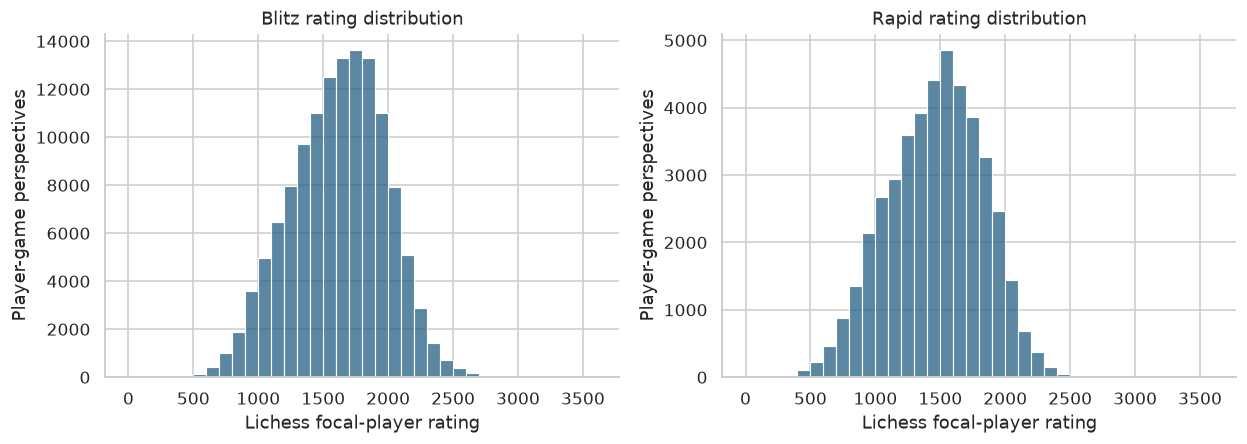

,count,mean,std,min,25%,50%,75%,max
speed,,,,,,,,
blitz,"129,648.000","1,615.900",366.300,400.000,"1,363.000","1,638.000","1,879.000","3,055.000"
rapid,"44,252.000","1,465.400",367.200,400.000,"1,207.000","1,487.000","1,732.000","3,066.000"


In [11]:
# We plot focal-player ratings separately for blitz and rapid, because the two rating scales differ.
fig, axes = plt.subplots(1,2,figsize=(11.5,4.2))
for ax,speed in zip(axes,["blitz","rapid"]):
    sub=perspectives[perspectives.speed.eq(speed)]
    sns.histplot(data=sub,x="player_rating",bins=np.arange(0,3601,100),ax=ax,color="#255F85")
    ax.set(title=f"{speed.title()} rating distribution",xlabel="Lichess focal-player rating",ylabel="Player-game perspectives")
fig.tight_layout();save_figure("W2_01_distribution.png")
display(perspectives.groupby("speed").player_rating.describe().round(1))

**Distribution interpretation:** observed play spans several rating bands, but the
histograms describe player-game opportunities, not numbers of independent people.
Keeping separate speeds avoids interpreting their rating scales as a common ability test.

,speed,color,rating_band,opening_family_20,games_all,score_pct_all,games_close,score_pct_close,change_pp
55,blitz,black,Under 1200,King's Knight Opening,84,47.024,64.000,58.594,11.570
1803,rapid,white,2000+,French Defense,88,48.295,55.000,39.091,-9.205
957,blitz,white,2000+,Nimzowitsch Defense,105,56.190,73.000,47.260,-8.930
1036,rapid,black,Under 1200,Englund Gambit,65,57.692,50.000,66.000,8.308
514,blitz,white,Under 1200,Bird Opening,62,56.452,51.000,64.706,8.254
425,blitz,black,2000+,Hungarian Opening,87,50.000,63.000,42.857,-7.143
1035,rapid,black,Under 1200,English Opening,98,44.388,68.000,51.471,7.083
1504,rapid,white,Under 1200,Petrov's Defense,156,54.487,112.000,61.161,6.674
0,blitz,black,Under 1200,Alekhine Defense,81,44.444,60.000,50.833,6.389
1551,rapid,white,1200-1599,Bird Opening,61,54.098,50.000,60.000,5.902


**Revised training agenda:** highest-exposure supported family per speed × color × level among close-rating opponents. This is a descriptive review priority, not an estimated benefit of studying or choosing the opening.

,speed,color,rating_band,opening_family_20_C1,opening_family_20_W2,games,score_pct,family_changed
0,blitz,black,1200-1599,Queen's Pawn Game,Queen's Pawn Game,1991,46.886,False
1,blitz,black,1600-1999,Sicilian Defense,Sicilian Defense,2811,47.705,False
2,blitz,black,2000+,Sicilian Defense,Sicilian Defense,1206,47.264,False
3,blitz,black,Under 1200,Queen's Pawn Game,Queen's Pawn Game,869,49.079,False
4,blitz,white,1200-1599,Queen's Pawn Game,Queen's Pawn Game,1992,53.790,False
5,blitz,white,1600-1999,Sicilian Defense,Sicilian Defense,2832,51.907,False
6,blitz,white,2000+,Sicilian Defense,Sicilian Defense,1193,53.730,False
7,blitz,white,Under 1200,Queen's Pawn Game,Queen's Pawn Game,870,49.425,False
8,rapid,black,1200-1599,Queen's Pawn Game,Queen's Pawn Game,803,48.879,False
9,rapid,black,1600-1999,Sicilian Defense,Sicilian Defense,767,51.630,False


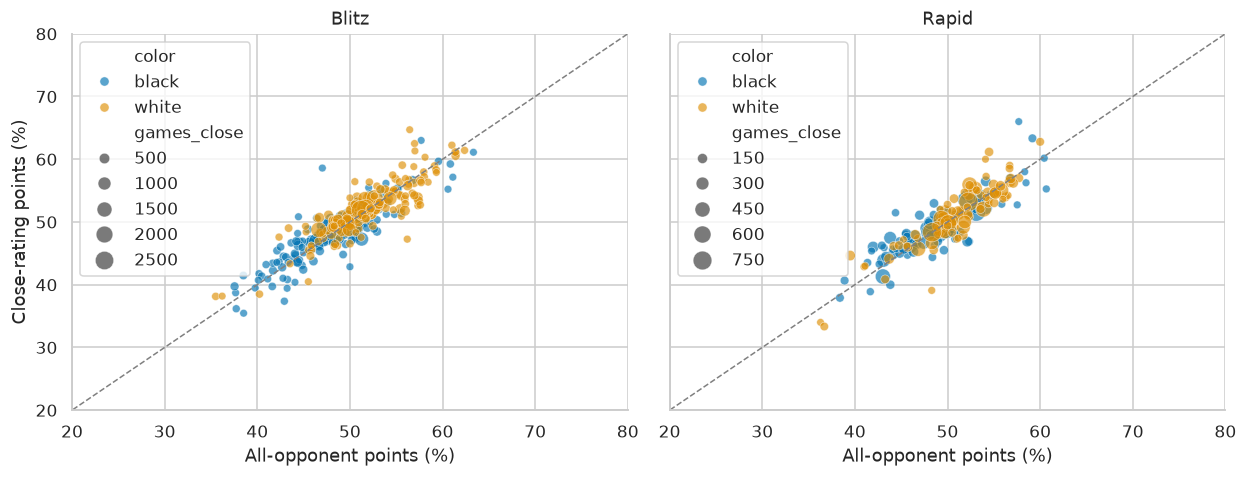

In [12]:
# We recompute the same points KPI using only opponents within 100 rating points and compare
# each cell with its all-opponent value, to see how much opponent strength moves the signal.
raw_kpi = kpi_table(perspectives)
balanced_views = perspectives[perspectives.balanced_opponents]
close_kpi = kpi_table(balanced_views)
join_cols=["speed","color","rating_band","opening_family_20"]
# validate="one_to_one" makes the merge fail if any cell appeared twice on either side.
comparison = raw_kpi.merge(close_kpi,on=join_cols,how="left",suffixes=("_all","_close"),validate="one_to_one")
comparison["change_pp"] = comparison.score_pct_close-comparison.score_pct_all
# Cells are paired by the exact same speed, color, focal level and family.
supported = comparison[(comparison.games_all>=MIN_CELL_GAMES)&(comparison.games_close>=MIN_CELL_GAMES)].copy()
display(supported.reindex(supported.change_pp.abs().sort_values(ascending=False).index).head(14)[join_cols+["games_all","score_pct_all","games_close","score_pct_close","change_pp"]])
# The revised agenda keeps, per speed x color x band, the most frequent supported family;
# sort then groupby(...).head(1) takes the top row of each group.
agenda_keys=["speed","color","rating_band"]
close_candidates=close_kpi[close_kpi.display_eligible & close_kpi.opening_family_20.ne("Unclassified")].copy()
close_agenda=close_candidates.sort_values(agenda_keys+["games","opening_family_20"],ascending=[True,True,True,False,True]).groupby(agenda_keys,observed=True).head(1)
c1_agenda=pd.read_csv(TABLES/"C1_training_agenda.csv")
agenda_change=c1_agenda[agenda_keys+["opening_family_20"]].merge(close_agenda[agenda_keys+["opening_family_20","games","score_pct"]],on=agenda_keys,how="outer",suffixes=("_C1","_W2"),validate="one_to_one")
agenda_change["family_changed"]=agenda_change.opening_family_20_C1.ne(agenda_change.opening_family_20_W2)
display(Markdown("**Revised training agenda:** highest-exposure supported family per speed × color × level among close-rating opponents. This is a descriptive review priority, not an estimated benefit of studying or choosing the opening."))
display(agenda_change)
close_agenda.to_csv(TABLES/"W2_training_agenda.csv",index=False)
agenda_change.to_csv(TABLES/"W2_agenda_changes.csv",index=False)
comparison.to_csv(TABLES / "W2_close_rating_comparison.csv",index=False)
# Points on the dashed diagonal did not change after the close-rating restriction.
fig,axes=plt.subplots(1,2,figsize=(11.5,4.5),sharex=True,sharey=True)
for ax,speed in zip(axes,["blitz","rapid"]):
    sub=supported[supported.speed.eq(speed)]
    sns.scatterplot(data=sub,x="score_pct_all",y="score_pct_close",hue="color",size="games_close",sizes=(25,160),alpha=.65,ax=ax)
    ax.plot([0,100],[0,100],color="gray",linestyle="--",linewidth=1)
    ax.set(xlim=(20,80),ylim=(20,80),title=speed.title(),xlabel="All-opponent points (%)",ylabel="Close-rating points (%)")
fig.tight_layout();save_figure("W2_02_close_rating_comparison.png")

In [13]:
# We report the single largest supported change in words, using the computed values only.
largest = supported.loc[supported.change_pp.abs().idxmax()] if len(supported) else None
if largest is not None:
    display(Markdown(f"""**Visible revision.** In the largest supported change, **{largest.opening_family_20}**
    for **{largest.color} / {largest.speed} / {largest.rating_band}** changes from
    **{largest.score_pct_all:.2f}% (n={largest.games_all:,.0f})** to
    **{largest.score_pct_close:.2f}% (n={largest.games_close:,.0f})**, a change of
    **{largest.change_pp:+.2f} percentage points**, after restricting opponent rating gaps.
    The observations are not corrected into causal effects: the comparison population
    changes, coverage falls and other confounders remain. C1's unadjusted figures remain
    valid descriptions; their use for review prioritisation becomes more conditional."""))

**Visible revision.** In the largest supported change, **King's Knight Opening**
    for **black / blitz / Under 1200** changes from
    **47.02% (n=84)** to
    **58.59% (n=64)**, a change of
    **+11.57 percentage points**, after restricting opponent rating gaps.
    The observations are not corrected into causal effects: the comparison population
    changes, coverage falls and other confounders remain. C1's unadjusted figures remain
    valid descriptions; their use for review prioritisation becomes more conditional.

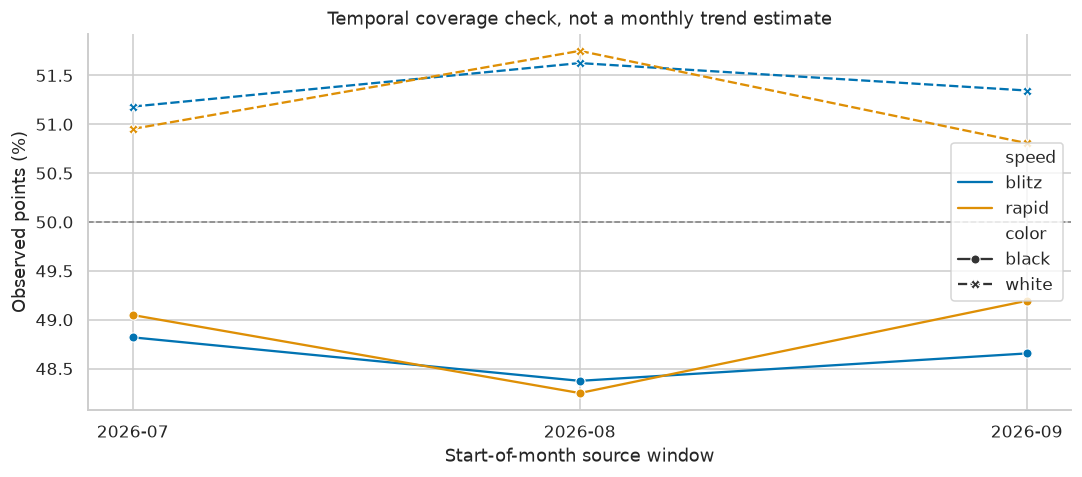

,source_month,speed,color,games,score_pct
0,2026-07,blitz,black,22950,48.819
1,2026-07,blitz,white,22950,51.181
2,2026-07,rapid,black,7665,49.048
3,2026-07,rapid,white,7665,50.952
4,2026-08,blitz,black,19128,48.374
5,2026-08,blitz,white,19128,51.626
6,2026-08,rapid,black,6654,48.249
7,2026-08,rapid,white,6654,51.751
8,2026-09,blitz,black,22746,48.655
9,2026-09,blitz,white,22746,51.345


In [14]:
# We compare points per source window, speed and color as a coverage check, not as a trend.
# nunique counts each game once even though it has two color rows.
month_view = perspectives.groupby(["source_month","speed","color"],observed=True).agg(games=("game_id","nunique"),score_pct=("score",lambda x:100*x.mean())).reset_index()
fig,ax=plt.subplots(figsize=(10,4.5))
sns.lineplot(data=month_view,x="source_month",y="score_pct",hue="speed",style="color",markers=True,errorbar=None,ax=ax)
ax.axhline(50,color="gray",linestyle="--",linewidth=1)
ax.set(xlabel="Start-of-month source window",ylabel="Observed points (%)",title="Temporal coverage check, not a monthly trend estimate")
fig.tight_layout();save_figure("W2_03_window_comparison.png")
display(month_view)
month_view.to_csv(TABLES / "W2_window_comparison.csv",index=False)

**Additional-view interpretation:** every point represents a short window on the first
UTC day of a month, not that month's full activity. White and Black scores are
complementary. Differences across windows may reflect who played or which openings
appeared; a line joining them does not establish a platform-wide trend.

## 5. Sampling and representativeness

The 25% exercise below samples unique **games**, stratified by speed and White's
rating band with fixed seed 423. Both color perspectives follow the sampled game IDs.
It compares White's points KPI separately in blitz and rapid, plus the rapid segment proportion,
against the complete available cohort. Group rounding can make the retained fraction
slightly different from exactly 25%. No source-selection bias is repaired by this step.

At least four distinct biases remain: start-of-month/UTC-time coverage, selection into
rated Lichess play, survival to 20 plies, and concentration of games among repeated
users. Splitting observations evaluates a specified prediction task; it does not
demonstrate that those observations represent the intended population.

In [15]:
# We draw a fixed-seed 25% sample of games within each speed x White rating band, then compare
# its KPI and segment shares with the full cohort. random_state=SEED makes the draw repeatable.
frame = games.assign(white_band=pd.cut(games.white_rating,RATING_EDGES,labels=RATING_LABELS,right=False))
sampled_groups=[]
for stratum,group in frame.groupby(["speed","white_band"],observed=True,sort=True):
    sampled_groups.append(group.sample(n=max(1,round(.25*len(group))),random_state=SEED))
sample=pd.concat(sampled_groups,ignore_index=True)
assert sample.game_id.is_unique and set(sample.game_id).issubset(games.game_id)
# Each row compares one measure in the complete cohort and in the sample.
sample_comparison=pd.DataFrame([
    {"measure":"White blitz points (%)","complete":100*games.loc[games.speed.eq("blitz"),"white_score"].mean(),"sample_25pct":100*sample.loc[sample.speed.eq("blitz"),"white_score"].mean()},
    {"measure":"White rapid points (%)","complete":100*games.loc[games.speed.eq("rapid"),"white_score"].mean(),"sample_25pct":100*sample.loc[sample.speed.eq("rapid"),"white_score"].mean()},
    {"measure":"Rapid game share (%)","complete":100*games.speed.eq("rapid").mean(),"sample_25pct":100*sample.speed.eq("rapid").mean()},
    {"measure":"White rating 2000+ share (%)","complete":100*games.white_rating.ge(2000).mean(),"sample_25pct":100*sample.white_rating.ge(2000).mean()},
])
sample_comparison["difference_pp"]=sample_comparison.sample_25pct-sample_comparison.complete
display(sample_comparison)
print(f"Sample: {len(sample):,}/{len(games):,} games ({len(sample)/len(games):.3%}).")
# crosstab(normalize="all") shows each speed x band share of all games, before and after sampling.
display(pd.crosstab(frame.speed,frame.white_band,normalize="all").round(4))
display(pd.crosstab(sample.speed,sample.white_band,normalize="all").round(4))
sample[["game_id"]].to_csv(ROOT/"data/splits/sample_25pct_ids.csv",index=False)
sample_comparison.to_csv(TABLES/"W2_sampling_comparison.csv",index=False)

,measure,complete,sample_25pct,difference_pp
0,White blitz points (%),51.370,51.463,0.093
1,White rapid points (%),51.141,52.043,0.901
2,Rapid game share (%),25.447,25.450,0.003
3,White rating 2000+ share (%),12.367,12.366,-0.001


Sample: 21,737/86,950 games (24.999%).


white_band,Under 1200,1200-1599,1600-1999,2000+
speed,,,,
blitz,0.107,0.237,0.294,0.108
rapid,0.062,0.097,0.080,0.016


white_band,Under 1200,1200-1599,1600-1999,2000+
speed,,,,
blitz,0.106,0.237,0.294,0.108
rapid,0.062,0.097,0.080,0.016


In [16]:
# We write the sampling result in words from the computed differences.
display(Markdown(f"""**Sampling interpretation.** The 25% within-frame sample changes White's blitz points
by **{sample_comparison.iloc[0].difference_pp:+.3f} pp**, White's rapid points by
**{sample_comparison.iloc[1].difference_pp:+.3f} pp**, and the rapid share by
**{sample_comparison.iloc[2].difference_pp:+.3f} pp**. These are observed differences
for one fixed-seed sample, not a guarantee for all possible samples or evidence of
platform representativeness. The original source windows are unchanged."""))

**Sampling interpretation.** The 25% within-frame sample changes White's blitz points
by **+0.093 pp**, White's rapid points by
**+0.901 pp**, and the rapid share by
**+0.003 pp**. These are observed differences
for one fixed-seed sample, not a guarantee for all possible samples or evidence of
platform representativeness. The original source windows are unchanged.

## 6. Context-specific leakage audit

**Decision/prediction instant:** immediately after Black's 10th move on a nonterminal
board. Ratings and configured clocks predate the result; the opening family is
reconstructed from the prefix already observed. Full-game classifications, results,
eventual move counts and post-game rating changes are unavailable at that instant.
A curricular decision uses historical summaries; it is not a recommendation that
chooses an opening for a player before the game begins.

In [17]:
# We test concrete leakage risks: final tags versus prefix labels, players shared across
# July and September, the predictor allow-list, and split membership of both color views.
tag_disagreement=int(games.final_family_post.ne(games.opening_family_20).sum())
def players_in(part):
    return set(part.white_id)|set(part.black_id)
overlapping_players=len(players_in(train)&players_in(test))
all_predictor_columns=set(FEATURES)
assert not all_predictor_columns.intersection(POST_OUTCOME_FIELDS+["game_id","white_id","black_id","source_month","start_utc"])
# Invariance check: changing unavailable fields cannot alter the prefix-derived feature.
probe=games.head(100).copy()
classifier=prefix_classifier(opening_index)
before=probe.prefix_san_20.map(classifier)
probe["result"]="0-1";probe["final_opening"]="FAKE FUTURE TAG";probe["white_rating_diff_post"]=999
after=probe.prefix_san_20.map(classifier)
assert before.equals(after)
# Two color views must always inherit the unique game's split.
membership_views=perspectives[["game_id","color"]].merge(membership,on="game_id",validate="many_to_one")
assert membership_views.groupby("game_id").subset.nunique().eq(1).all()
# The audit table records each risk with its status, evidence, consequence and mitigation.
leakage=pd.DataFrame([
    {"risk":"Post-outcome predictors","status":"present in raw; absent from X","evidence":f"{sum(x in raw for x in POST_OUTCOME_FIELDS)} audited source fields; explicit {len(FEATURES)}-field allow-list","consequence":"Outcome proxies could inflate apparent accuracy","mitigation":"Exclude result, termination, rating changes and full move count"},
    {"risk":"Final opening versus observed prefix","status":"present as availability risk; excluded from X","evidence":f"{tag_disagreement:,} family labels differ; 100 changed-future-field probes leave prefix labels unchanged","consequence":"A final tag can describe later play; differences can also reflect taxonomy","mitigation":"Fixed position lookup using at most 20 observed plies"},
    {"risk":"Duplicate games or opposite-color copies across sets","status":"absent after checks","evidence":"Game IDs pairwise disjoint; each game's color views inherit one subset","consequence":"The same realised game could appear in fit and evaluation","mitigation":"Split unique games first; assert many-to-one view membership"},
    {"risk":"Repeated players","status":"present; task-dependent boundary","evidence":f"{overlapping_players:,} player IDs occur in both July train and September test","consequence":"Evaluation is not for unseen people; outcomes are dependent","mitigation":"No player IDs/history features; disclose future-play task. A new-player task needs a separate both-opponents grouping design"},
    {"risk":"Preprocessing learned on evaluation sets","status":"prevented by implementation","evidence":"Section 7 fits one ColumnTransformer on July only; its parameters remain unchanged after transform","consequence":"Evaluation distribution could influence training","mitigation":"fit on train, transform validation/test without refitting"},
    {"risk":"Previously explored test outcomes","status":"present","evidence":"C1 inspected the whole cohort; September is included in C1 fingerprint","consequence":"Cannot claim a pristine confirmatory evaluation","mitigation":"No tuning or predictive score here; freeze contract and require new data for confirmatory evaluation"},
    {"risk":"Outcome-dependent linked features","status":"absent from implemented X","evidence":"Opening lookup uses names/positions only, not ratings or outcomes; no global target encoding","consequence":"Full-cohort win rates encoded into features would leak labels","mitigation":"Keep descriptive KPI tables outside X; fit any future target encoding inside training folds"},
])
display(leakage)
leakage.to_csv(TABLES/"W2_leakage_audit.csv",index=False)

,risk,status,evidence,consequence,mitigation
0,Post-outcome predictors,present in raw; absent from X,7 audited source fields; explicit 7-field allo...,Outcome proxies could inflate apparent accuracy,"Exclude result, termination, rating changes an..."
1,Final opening versus observed prefix,present as availability risk; excluded from X,311 family labels differ; 100 changed-future-f...,A final tag can describe later play; differenc...,Fixed position lookup using at most 20 observe...
2,Duplicate games or opposite-color copies acros...,absent after checks,Game IDs pairwise disjoint; each game's color ...,The same realised game could appear in fit and...,Split unique games first; assert many-to-one v...
3,Repeated players,present; task-dependent boundary,"3,112 player IDs occur in both July train and ...",Evaluation is not for unseen people; outcomes ...,No player IDs/history features; disclose futur...
4,Preprocessing learned on evaluation sets,prevented by implementation,Section 7 fits one ColumnTransformer on July o...,Evaluation distribution could influence training,"fit on train, transform validation/test withou..."
5,Previously explored test outcomes,present,C1 inspected the whole cohort; September is in...,Cannot claim a pristine confirmatory evaluation,No tuning or predictive score here; freeze con...
6,Outcome-dependent linked features,absent from implemented X,"Opening lookup uses names/positions only, not ...",Full-cohort win rates encoded into features wo...,Keep descriptive KPI tables outside X; fit any...


Repeated players are not automatically an error for a declared future-play task;
a genuinely unseen-player task is a different generalisation claim. Grouping only
by White's ID would not protect against the same player appearing as Black. The
current project does not claim such independence or fit player-specific effects.

## 7. Train-only learned preprocessing and implemented validation plan

July is the fitting subset; August is an internal validation subset reserved for
future choices; September is the temporal test subset. No model selection happens
in W2. A non-80/20 allocation is justified by the available calendar blocks, not by
tuning observed performance. If later refitting on July+August after choices are
frozen, all learned preprocessing must be fitted again on that development pool
and evaluated once on genuinely suitable future test data.

In [18]:
# We learn scaling and category lists from July only, then apply those frozen rules to
# August and September. No model is fitted.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import sklearn
# ColumnTransformer applies StandardScaler (subtract mean, divide by spread) to ratings and clocks,
# and OneHotEncoder (one 0/1 column per category) to speed and family; handle_unknown="ignore"
# encodes a family unseen in July as all zeros instead of failing.
preprocessor=ColumnTransformer([
    ("numeric",StandardScaler(),NUMERIC_FEATURES),
    ("categorical",OneHotEncoder(handle_unknown="ignore",sparse_output=False),CATEGORICAL_FEATURES),
],remainder="drop")
X_train=train[FEATURES].copy();y_train=train.outcome.copy()
X_validation=validation[FEATURES].copy();y_validation=validation.outcome.copy()
X_test=test[FEATURES].copy();y_test=test.outcome.copy()
assert X_train.notna().all().all() and X_validation.notna().all().all() and X_test.notna().all().all()
# fit learns parameters (means, scales, categories); transform only applies them.
# We fit on July once and only transform August and September.
train_transformed=preprocessor.fit_transform(X_train)
scaler=preprocessor.named_transformers_["numeric"]
means_before=scaler.mean_.copy();scales_before=scaler.scale_.copy()
validation_transformed=preprocessor.transform(X_validation)
test_transformed=preprocessor.transform(X_test)
# These asserts prove the learned values did not change and came only from July rows.
assert np.allclose(means_before,scaler.mean_)
assert np.allclose(scales_before,scaler.scale_)
assert np.allclose(means_before,X_train[NUMERIC_FEATURES].mean().to_numpy())
assert int(scaler.n_samples_seen_)==len(train)
# Future outcomes are never passed to fit. No model is being fitted here.
learned=pd.DataFrame({"feature":NUMERIC_FEATURES,"train_mean_learned":means_before,
                      "train_scale_learned":scales_before,"full_cohort_mean_not_used":games[NUMERIC_FEATURES].mean().to_numpy()})
display(learned)
transformed_counts=pd.DataFrame({"subset":["train","validation","test"],
                                "rows":[len(train_transformed),len(validation_transformed),len(test_transformed)],
                                "encoded_columns":[train_transformed.shape[1]]*3})
display(transformed_counts)
# We count rows whose category never appeared in July; these are the ones handled by "ignore".
unseen=pd.DataFrame([{ "subset":name,"feature":col,
                      "unknown_rows":int((~part[col].isin(train[col].unique())).sum())}
                     for name,part in [("validation",validation),("test",test)] for col in CATEGORICAL_FEATURES])
display(unseen)
learned.to_csv(TABLES/"W2_train_only_parameters.csv",index=False)
unseen.to_csv(TABLES/"W2_unknown_categories.csv",index=False)
# We save the transformed arrays and a record of the learned parameters for inspection.
np.savez_compressed(ROOT/"data/splits/transformed_features.npz",train=train_transformed,
                    validation=validation_transformed,test=test_transformed,
                    feature_names=np.asarray(preprocessor.get_feature_names_out(),dtype=str))
pd.Series(preprocessor.get_feature_names_out(),name="encoded_feature").to_csv(ROOT/"data/splits/encoded_feature_names.csv",index=False)
preprocessing_record={"sklearn_version":sklearn.__version__,"fit_month":"2026-07","fit_game_count":len(train),
                      "numeric_means":dict(zip(NUMERIC_FEATURES,means_before.tolist())),
                      "numeric_scales":dict(zip(NUMERIC_FEATURES,scales_before.tolist())),
                      "categories":[x.tolist() for x in preprocessor.named_transformers_["categorical"].categories_],
                      "refitted_on_validation_or_test":False,"model_fitted":False}
(ROOT/"provenance/W2_preprocessing_record.json").write_text(json.dumps(preprocessing_record,indent=2))

,feature,train_mean_learned,train_scale_learned,full_cohort_mean_not_used
0,white_rating,"1,578.321",373.035,"1,577.427"
1,black_rating,"1,577.980",373.233,"1,577.708"
2,rating_gap,0.341,126.270,-0.281
3,base_seconds,321.331,179.281,322.999
4,increment_seconds,0.782,1.613,0.809


,subset,rows,encoded_columns
0,train,30615,144
1,validation,25782,144
2,test,30553,144


,subset,feature,unknown_rows
0,validation,speed,0
1,validation,opening_family_20,1
2,test,speed,0
3,test,opening_family_20,9


4451

Unknown families in later windows are encoded with the documented unknown handling;
they do not cause refitting on evaluation data. This can reduce information for those
cases, so the counts are retained. There was no need to invent missing ratings or
imputation just to demonstrate a learned operation: standardisation and one-hot
category learning already demonstrate training-only fitting.

**Future validation plan:** compare a simple rating-based reference with a small,
interpretable classifier only in development data; use August for decisions, then
freeze them. For a future three-class outcome, class-wise recall/confusion and
probability quality would need attention, especially for draws. These are proposed
checks, not implemented results. New dates and additional UTC windows are needed
before making a convincing generalisation or instructional-effectiveness claim.

## 8. Candidate extension for C2: competitive use of the points KPI

**Assumption.** Using the same points KPI defined in Section 1, a win counts 1, a draw
0.5 and a loss 0: the same scoring used in most chess tournaments. A club with a
competitive team could later reuse this KPI to estimate expected points against
opponents of different ratings, to look at its competitors individually rather than as
a mass, and to support decisions such as team line-ups or championship targets.

This is presented as a possible **second use of the same KPI**, not as a change of
project or a new decision. The opening-review decision, the checkpoint and the
methodology of Sections 1–7 remain unchanged. The cell below only observes the
prepared cohort; it fits nothing, tunes nothing and uses no subset for decisions.

In [19]:
# We label each prepared game by its Lichess event type, to see how much tournament play
# the source windows already contain. Nothing is exported and the summary is untouched.
# np.select picks the first matching condition: Arena URLs contain /tournament/, Swiss /swiss/.
event_kind=np.select([games.event.str.contains("/tournament/",regex=False),
                      games.event.str.contains("/swiss/",regex=False)],["arena","swiss"],"casual")
event_view=games.assign(event_kind=event_kind)
event_counts=event_view.groupby("event_kind").agg(games=("game_id","size"),distinct_events=("event","nunique"))
event_counts["share_pct"]=100*event_counts.games/len(games)
display(event_counts.reindex(["casual","arena","swiss"]))
display(event_view.groupby(["event_kind","speed"]).size().unstack(fill_value=0).reindex(["casual","arena","swiss"]))
# We count games per pseudonymous player across both colors, because any individual
# estimate depends on how many games each player contributes.
games_per_player=pd.concat([games.white_id,games.black_id]).value_counts()
display(games_per_player.describe(percentiles=[.5,.9,.99]).to_frame("games_per_player").T)
frequent_players=int(games_per_player.ge(10).sum())
display(Markdown(f"""**Observation.** The prepared cohort contains
**{event_counts.loc["casual","games"]:,}** casual rated games,
**{event_counts.loc["arena","games"]:,}** Arena tournament games from
**{event_counts.loc["arena","distinct_events"]:,}** distinct events and
**{event_counts.loc["swiss","games"]:,}** Swiss games from
**{event_counts.loc["swiss","distinct_events"]:,}** distinct events.
Across **{len(games_per_player):,}** players, the median is
**{games_per_player.median():.0f}** games per player, the maximum is
**{games_per_player.max():,}**, and **{frequent_players:,}** players have at least 10 games."""))

,games,distinct_events,share_pct
event_kind,,,
casual,77900,2,89.592
arena,8554,295,9.838
swiss,496,61,0.570


speed,blitz,rapid
event_kind,,
casual,57964,19936
arena,6584,1970
swiss,276,220


,count,mean,std,min,50%,90%,99%,max
games_per_player,"70,742.000",2.458,2.072,1.000,2.000,5.000,10.000,37.000


**Observation.** The prepared cohort contains
**77,900** casual rated games,
**8,554** Arena tournament games from
**295** distinct events and
**496** Swiss games from
**61** distinct events.
Across **70,742** players, the median is
**2** games per player, the maximum is
**37**, and **926** players have at least 10 games.

**Assumption: background and what would remain for C2.** These points record why the
direction may be worth studying later; none of them is a feasibility verdict.

- The data already contain tournament games, but the short start-of-month windows cut
  tournaments, so complete events are not observed. Lichess Arena scoring is not
  1 / 0.5 / 0 (streaks and berserk change points); Swiss events are closer to a championship.
- With few games per player, an individual estimate would need comparison against
  Elo-expected points and shrinkage towards the average. This remains future work.
- Before a tournament game the opening is unknown. A competitive use would move the
  decision instant away from ply 20 and would need to pass the leakage audit again.
- Data that could be explored in C2: complete tournament results from the public Lichess
  API, longer per-player histories and, for over-the-board events, FIDE ratings. These are
  possibilities to review; their availability has not been verified here.

This is recorded as a candidate direction for C2 and the later machine-learning stage;
no feasibility conclusion or model is claimed in W2.

## 9. Management interpretation and next step

In [20]:
# We write the 120-180-word management summary from computed values and save the W2 summary JSON
# that the Spanish report reads; the assert enforces the word limit.
management_summary=f"""This revision retains C1's opening-review decision and color-specific points KPI for {len(games):,} eligible games. It adds explicit data-validation results, a reproducible 25% within-frame sample, a context-specific leakage audit and chronological July training, August validation and September test files. C1's unadjusted opening scores remain descriptive; the close-rating comparison shows that review signals can change when opponent strength is restricted. Opening families are reconstructed from the first twenty plies, while final tags and post-game rating changes are excluded from predictors. The scaler and category encoder learn only from July. No predictive model or performance claim is presented. The source covers three short start-of-month UTC windows, repeated players and games reaching the checkpoint, so findings cannot represent all Lichess play or demonstrate training benefits. September was already explored in C1 and is not pristine. The close-rating agenda identifies a supported, frequent family per level, color and speed for review, not opening superiority. Next, expand temporal coverage and reserve new data before evaluating a classifier."""
word_count=len(management_summary.split())
assert 120<=word_count<=180,word_count
display(Markdown(management_summary))
print("Management summary words:",word_count)
(ROOT/"outputs/W2_management_summary.txt").write_text(management_summary)
w2_summary={"prepared_games":len(games),"prepared_fingerprint":prepared_fingerprint(games),
            "split_counts":{k:len(v) for k,v in partitions.items()},"sample_games":len(sample),
            "sampling_comparison":sample_comparison.to_dict("records"),
            "supported_close_rating_cells":len(supported),"player_train_test_overlap":overlapping_players,
            "training_agenda_cells":len(close_agenda),"agenda_family_changes_from_C1":int(agenda_change.family_changed.sum()),
            "final_prefix_family_disagreements":tag_disagreement,"management_summary_words":word_count,
            "model_fitted":False,"test_set_pristine":False,"seed":SEED}
if largest is not None:
    w2_summary["largest_supported_change"]={k:str(largest[k]) for k in join_cols}
    w2_summary["largest_supported_change"].update({k:float(largest[k]) for k in ["games_all","score_pct_all","games_close","score_pct_close","change_pp"]})
(ROOT/"outputs/W2_summary.json").write_text(json.dumps(w2_summary,indent=2))

This revision retains C1's opening-review decision and color-specific points KPI for 86,950 eligible games. It adds explicit data-validation results, a reproducible 25% within-frame sample, a context-specific leakage audit and chronological July training, August validation and September test files. C1's unadjusted opening scores remain descriptive; the close-rating comparison shows that review signals can change when opponent strength is restricted. Opening families are reconstructed from the first twenty plies, while final tags and post-game rating changes are excluded from predictors. The scaler and category encoder learn only from July. No predictive model or performance claim is presented. The source covers three short start-of-month UTC windows, repeated players and games reaching the checkpoint, so findings cannot represent all Lichess play or demonstrate training benefits. September was already explored in C1 and is not pristine. The close-rating agenda identifies a supported, frequent family per level, color and speed for review, not opening superiority. Next, expand temporal coverage and reserve new data before evaluating a classifier.

Management summary words: 161


1601

## AI-use disclosure and reproducibility

AI assisted source discovery, code and writing. The group supplied the topic,
recent-data preference, multiple levels, both speeds and local-only delivery.
Verification includes source hashes, actual row counts, legal-prefix reconstruction,
C1/W2 cohort fingerprint equality, pairwise split-ID disjointness, color-view
inheritance, future-field invariance and training-only learned parameters. Both
notebooks are executed with saved outputs. Individual review and understanding
remain the members' responsibility; no personal contribution or reflection is invented.

The same fixed seed is used wherever randomness occurs. All files use project-relative
paths. Run this notebook after the supplied C1 baseline; the baseline JSON is shipped
so continuity checks can also be inspected without rebuilding C1 first. The local
package intentionally has no GitHub commit/tag: add those only if the team later
publishes it. See README for execution, provenance and the exact scope of this version.

## Sources and methodological references

1. [Lichess open database](https://database.lichess.org/#standard_games), official monthly standard-rated PGN archives, July–September 2026; retrieved 21 October 2026; CC0.
2. [Lichess opening names](https://github.com/lichess-org/chess-openings), commit recorded in `provenance/source_manifest.json`; CC0; position matching and family-name convention.
3. [Lichess FAQ](https://lichess.org/faq), speed estimated by base seconds + 40 × increment; blitz 180–479 seconds and rapid 480–1499 seconds.
4. [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), training-only fitting and leakage prevention.
5. Course C1 brief/rubric, W2 brief/rubric, Classes 01–04 and course calendar supplied with this project. Local originals are outside this package in the parent workspace; `provenance/course_sources.json` records filenames and checksums.

This is an educational observatory proposed by the team, not an evaluation commissioned
by Lichess or a real club. Statistical significance and predictive performance are not
claimed. Source code, reduced inputs and saved notebook outputs make calculations inspectable.